**TRANING PROCESSES**

In [908]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import  confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

import pandas as pd
import numpy as np

In [909]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

**READ THE DATA**

In [910]:
# Training data
train_df = pd.read_csv("../data/obesity_train.csv")
train_df.head()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,Gender_Male,family_history_with_overweight_yes,...,CAEC_Frequently,CAEC_Sometimes,CAEC_no,SMOKE_yes,SCC_yes,CALC_Sometimes,CALC_no,MTRANS_Private_Motorized,MTRANS_Public,is_obesity
0,37.638102,1.750085,118.114184,2.073224,3.000000,2.024035,0.131371,0.000000,1,1,...,0,1,0,0,0,1,0,1,0,1
1,20.914366,1.644751,101.067988,2.801992,1.343117,1.128942,0.233987,0.819980,1,1,...,0,1,0,0,0,0,1,0,1,1
2,20.102241,1.816868,153.959945,3.000000,3.000000,2.414739,1.917014,0.927982,0,1,...,0,1,0,0,0,1,0,0,1,1
3,20.244359,1.559186,41.952805,2.619835,1.000000,1.198883,0.000000,0.751212,0,0,...,1,0,0,0,0,1,0,0,1,0
4,22.538932,1.603963,82.012637,1.123672,1.014916,2.042078,1.846666,1.426103,0,1,...,0,1,0,0,0,0,1,0,1,1


In [911]:
# Testing data 
test_df = pd.read_csv("../data/obesity_test.csv")
test_df.head()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,Gender_Male,family_history_with_overweight_yes,...,CAEC_Frequently,CAEC_Sometimes,CAEC_no,SMOKE_yes,SCC_yes,CALC_Sometimes,CALC_no,MTRANS_Private_Motorized,MTRANS_Public,is_obesity
0,20.000000,1.800000,114.000000,2.000000,3.000000,2.000000,0.000000,1.0,1,1,...,1,0,0,0,0,0,1,0,1,1
1,23.018443,1.584785,44.376637,2.204914,2.127797,2.120292,0.995735,0.0,0,0,...,1,0,0,0,0,0,1,0,1,0
2,23.000000,1.630000,45.000000,3.000000,3.000000,3.000000,2.000000,0.0,0,1,...,0,1,0,0,1,0,1,0,1,0
3,41.000000,1.800000,92.000000,2.000000,1.000000,3.000000,1.000000,0.0,1,1,...,1,0,0,0,0,1,0,1,0,0
4,17.000000,1.600000,53.000000,1.000000,3.000000,1.000000,2.000000,2.0,0,0,...,0,1,0,0,0,1,0,0,0,0


In [912]:
# Model Logistic Regression
model = LogisticRegression(max_iter=1000, random_state=42)

**GENERAL TRAINING**


In [913]:
# In this case all features are used to train the model
features = train_df.drop(columns=['is_obesity'])
print(train_df[features.columns].describe())

X = train_df[features.columns]
y = train_df['is_obesity']

               Age       Height       Weight         FCVC          NCP  \
count  1419.000000  1419.000000  1419.000000  1419.000000  1419.000000   
mean     24.200317     1.703524    86.788894     2.415931     2.714083   
std       6.229054     0.091010    26.238006     0.538333     0.756057   
min      14.000000     1.481682    39.101805     1.000000     1.000000   
25%      19.727886     1.633107    65.407961     2.000000     2.746306   
50%      22.717943     1.704877    83.000000     2.392665     3.000000   
75%      26.000000     1.768233   107.430682     3.000000     3.000000   
max      55.246250     1.980000   165.057269     3.000000     4.000000   

              CH2O          FAF          TUE  Gender_Male  \
count  1419.000000  1419.000000  1419.000000  1419.000000   
mean      2.010990     1.018292     0.688412     0.504581   
std       0.597566     0.853354     0.617775     0.500155   
min       1.000000     0.000000     0.000000     0.000000   
25%       1.622539     0.130

In [914]:
# Split the training data into features and target variable
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training set shape:", X_train.shape)
print("Validation set shape:", X_val.shape)
print("Training set target shape:", y_train.shape)
print("Validation set target shape:", y_val.shape)

Training set shape: (1135, 20)
Validation set shape: (284, 20)
Training set target shape: (1135,)
Validation set target shape: (284,)


In [915]:
# The X_train, X_val are not scaled, so we need to scale them before training the model. We will use StandardScaler for this purpose.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

In [916]:
# Start training the model and evaluate the model on the validation set
model.fit(X_train_scaled, y_train)

y_val_pred = model.predict(X_val_scaled)
print("\nClassification Report:\n", classification_report(y_val, y_val_pred))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_val_pred))



Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       152
           1       1.00      1.00      1.00       132

    accuracy                           1.00       284
   macro avg       1.00      1.00      1.00       284
weighted avg       1.00      1.00      1.00       284

Confusion Matrix:
 [[152   0]
 [  0 132]]


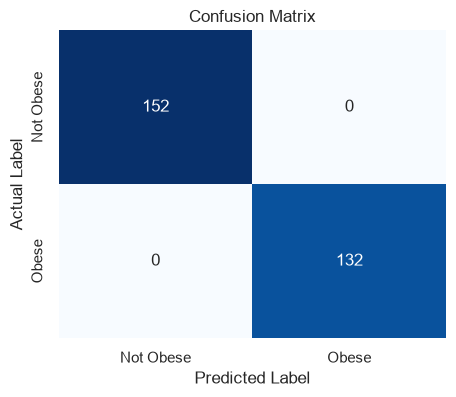

In [917]:
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not Obese", "Obese"],
    yticklabels=["Not Obese", "Obese"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [918]:
# evaluate the model on the test set
X_test = test_df[features.columns]
y_test = test_df['is_obesity']

# Scale the test set using the same scaler as the training set
X_test_scaled = scaler.transform(X_test)
y_test_pred = model.predict(X_test_scaled)
print("\nTest Set Classification Report:\n", classification_report(y_test, y_test_pred))
print("Test Set Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))


Test Set Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00       190
           1       1.00      0.99      1.00       165

    accuracy                           1.00       355
   macro avg       1.00      1.00      1.00       355
weighted avg       1.00      1.00      1.00       355

Test Set Confusion Matrix:
 [[190   0]
 [  1 164]]


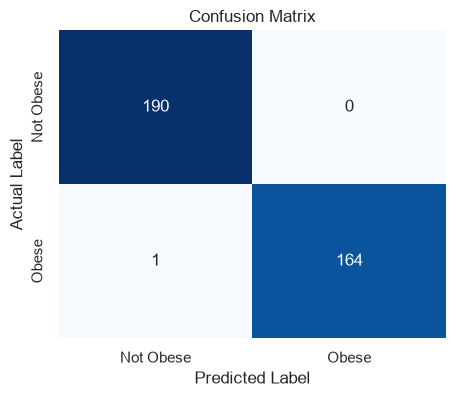

In [919]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not Obese", "Obese"],
    yticklabels=["Not Obese", "Obese"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

Conclusion that the model is perform well on predict obesity by using all features.

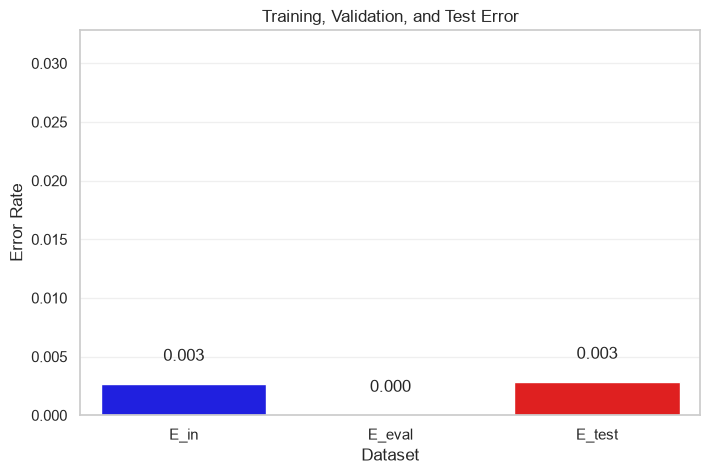

In [920]:
e_in = 1 - accuracy_score(y_train, model.predict(X_train_scaled))
e_eval = 1 - accuracy_score(y_val, y_val_pred)
e_test = 1 - accuracy_score(y_test, y_test_pred)

error_data = pd.DataFrame({
    "Dataset": ["E_in", "E_eval", "E_test"],
    "Error": [e_in, e_eval, e_test]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=error_data,
    x="Dataset",
    y="Error",
    hue="Dataset",
    palette=["blue", "orange", "red"],
    legend=False
)

for i, value in enumerate(error_data["Error"]):
    plt.text(
        i,
        value + 0.002,
        f"{value:.3f}",
        ha="center"
    )

plt.title("Training, Validation, and Test Error")
plt.xlabel("Dataset")
plt.ylabel("Error Rate")
plt.ylim(0, max(error_data["Error"]) + 0.03)
plt.grid(axis="y", alpha=0.3)

plt.show()

**QUESTION 1: Is that height and weight can determine the obesity?**

In [921]:
# Using only 2 features (Height and Weight) to train the model
train_Q1_X = train_df[['Height', 'Weight']]
train_Q1_y = train_df['is_obesity']


In [922]:
# split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(train_Q1_X, train_Q1_y, test_size=0.2, random_state=42, stratify=train_Q1_y)

# scaled the features using StandardScaler
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

In [923]:
model.fit(X_train_scaled, y_train) 
y_val_pred = model.predict(X_val_scaled)
print("report:\n", classification_report(y_val, y_val_pred))
print("confusion_matrix\n", confusion_matrix(y_val, y_val_pred))

report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       152
           1       1.00      1.00      1.00       132

    accuracy                           1.00       284
   macro avg       1.00      1.00      1.00       284
weighted avg       1.00      1.00      1.00       284

confusion_matrix
 [[152   0]
 [  0 132]]


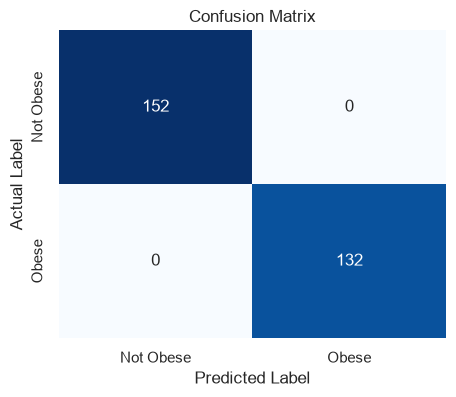

In [924]:
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not Obese", "Obese"],
    yticklabels=["Not Obese", "Obese"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


In [925]:
# Evaluate the model on the test set using only Height and Weight features
test_Q1_X = test_df[['Height', 'Weight']]
test_Q1_y = test_df['is_obesity']

In [926]:
# Scale the test set using the same scaler as the training set
X_test_scaled = scaler.transform(test_Q1_X)
y_test_pred = model.predict(X_test_scaled)
print("report:\n", classification_report(test_Q1_y, y_test_pred))
print("confusion_matrix\n", confusion_matrix(test_Q1_y, y_test_pred))

report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       190
           1       0.99      0.99      0.99       165

    accuracy                           0.99       355
   macro avg       0.99      0.99      0.99       355
weighted avg       0.99      0.99      0.99       355

confusion_matrix
 [[189   1]
 [  2 163]]


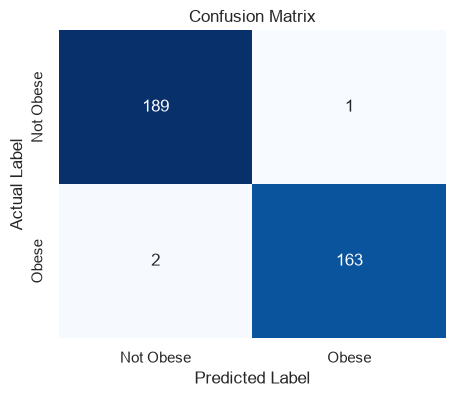

In [927]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not Obese", "Obese"],
    yticklabels=["Not Obese", "Obese"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [928]:
# Predictions
train_pred = model.predict(X_train_scaled)
val_pred = model.predict(X_val_scaled)
test_pred = model.predict(X_test_scaled)

# Calculate errors
e_in = 1 - accuracy_score(y_train, train_pred)
e_eval = 1 - accuracy_score(y_val, val_pred)
e_test = 1 - accuracy_score(y_test, test_pred)

print("e_in:", e_in)
print("e_eval:", e_eval)
print("e_test:", e_test)

e_in: 0.005286343612334821
e_eval: 0.0
e_test: 0.008450704225352101


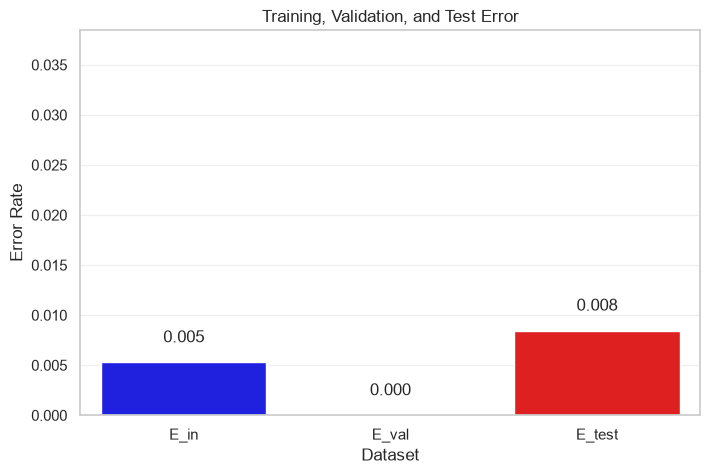

In [929]:
error_data = pd.DataFrame({
    "Dataset": ["E_in", "E_val", "E_test"],
    "Error": [e_in, e_eval, e_test]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=error_data,
    x="Dataset",
    y="Error",
    hue="Dataset",
    palette=["blue", "orange", "red"],
    legend=False
)

for i, value in enumerate(error_data["Error"]):
    plt.text(
        i,
        value + 0.002,
        f"{value:.3f}",
        ha="center"
    )

plt.title("Training, Validation, and Test Error")
plt.xlabel("Dataset")
plt.ylabel("Error Rate")
plt.ylim(0, max(error_data["Error"]) + 0.03)
plt.grid(axis="y", alpha=0.3)

plt.show()

Conclusion that the model can use 2 features and able to perform well on obesity prediction.

**Q2: Is that the lifestyle can predict the obesity status?**

In [930]:
# Prepare features and target for Q2
drop_cols = ["Height", "Weight", "is_obesity"]
train_Q2_X = train_df.drop(columns=drop_cols)
train_Q2_y = train_df["is_obesity"]

In [931]:
train_Q2_X.head() 

,Age,FCVC,NCP,CH2O,FAF,TUE,Gender_Male,family_history_with_overweight_yes,FAVC_yes,CAEC_Frequently,CAEC_Sometimes,CAEC_no,SMOKE_yes,SCC_yes,CALC_Sometimes,CALC_no,MTRANS_Private_Motorized,MTRANS_Public
0,37.638102,2.073224,3.000000,2.024035,0.131371,0.000000,1,1,1,0,1,0,0,0,1,0,1,0
1,20.914366,2.801992,1.343117,1.128942,0.233987,0.819980,1,1,1,0,1,0,0,0,0,1,0,1
2,20.102241,3.000000,3.000000,2.414739,1.917014,0.927982,0,1,1,0,1,0,0,0,1,0,0,1
3,20.244359,2.619835,1.000000,1.198883,0.000000,0.751212,0,0,1,1,0,0,0,0,1,0,0,1
4,22.538932,1.123672,1.014916,2.042078,1.846666,1.426103,0,1,1,0,1,0,0,0,0,1,0,1


In [932]:
# split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(train_Q2_X, train_Q2_y, test_size=0.2, random_state=42, stratify=train_Q2_y)

In [933]:
# Scale and train the model using the remaining features

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
model.fit(X_train_scaled, y_train)
y_val_pred = model.predict(X_val_scaled)
print("report:\n", classification_report(y_val, y_val_pred))
print("confusion_matrix\n", confusion_matrix(y_val, y_val_pred))

report:
               precision    recall  f1-score   support

           0       0.84      0.70      0.76       152
           1       0.71      0.84      0.77       132

    accuracy                           0.77       284
   macro avg       0.77      0.77      0.77       284
weighted avg       0.78      0.77      0.77       284

confusion_matrix
 [[107  45]
 [ 21 111]]


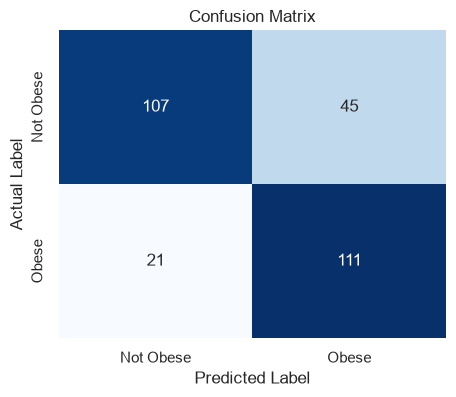

In [934]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not Obese", "Obese"],
    yticklabels=["Not Obese", "Obese"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [935]:
# Evaluate the model on the test set
test_Q2_X = test_df.drop(columns=drop_cols)
test_Q2_y = test_df["is_obesity"]

X_test_scaled = scaler.transform(test_Q2_X)
y_test_pred = model.predict(X_test_scaled)
print("report:\n", classification_report(test_Q2_y, y_test_pred))
print("confusion_matrix\n", confusion_matrix(test_Q2_y, y_test_pred))

report:
               precision    recall  f1-score   support

           0       0.83      0.73      0.78       190
           1       0.72      0.83      0.77       165

    accuracy                           0.77       355
   macro avg       0.78      0.78      0.77       355
weighted avg       0.78      0.77      0.77       355

confusion_matrix
 [[138  52]
 [ 28 137]]


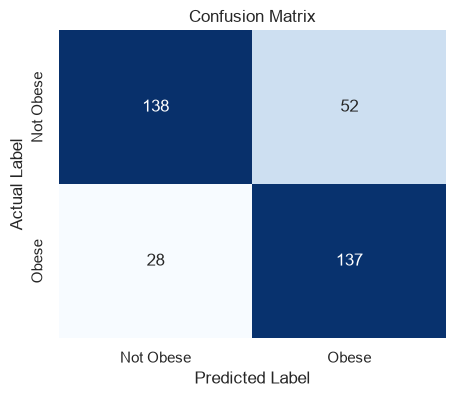

In [936]:
cm = confusion_matrix(test_Q2_y, y_test_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not Obese", "Obese"],
    yticklabels=["Not Obese", "Obese"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

e_in: 0.23524229074889869
e_eval: 0.23239436619718312
e_test: 0.22535211267605637


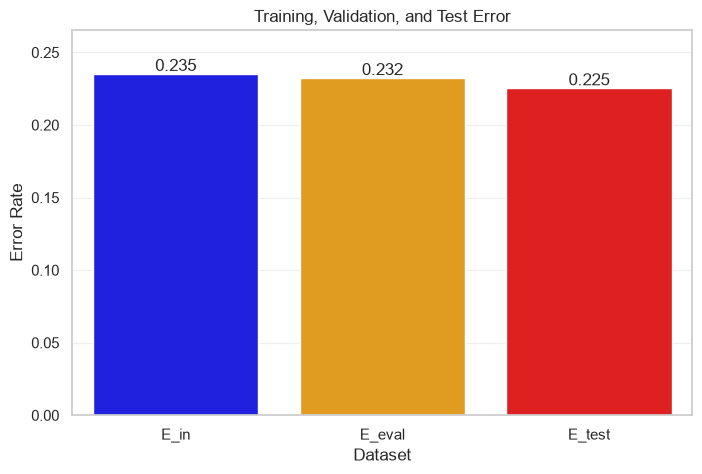

In [937]:
# Predictions
train_pred = model.predict(X_train_scaled)
val_pred = model.predict(X_val_scaled)
test_pred = model.predict(X_test_scaled)

# Calculate errors
e_in = 1 - accuracy_score(y_train, train_pred)
e_eval = 1 - accuracy_score(y_val, val_pred)
e_test = 1 - accuracy_score(y_test, test_pred)

print("e_in:", e_in)
print("e_eval:", e_eval)
print("e_test:", e_test)

error_data = pd.DataFrame({
    "Dataset": ["E_in", "E_eval", "E_test"],
    "Error": [e_in, e_eval, e_test]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=error_data,
    x="Dataset",
    y="Error",
    hue="Dataset",
    palette=["blue", "orange", "red"],
    legend=False
)

for i, value in enumerate(error_data["Error"]):
    plt.text(
        i,
        value + 0.002,
        f"{value:.3f}",
        ha="center"
    )

plt.title("Training, Validation, and Test Error")
plt.xlabel("Dataset")
plt.ylabel("Error Rate")
plt.ylim(0, max(error_data["Error"]) + 0.03)
plt.grid(axis="y", alpha=0.3)

plt.show()

As first the Logistic Regression look bad, the accuracy in both validation and test are low. This indicate that model are underfit/ the model is too simple to answer the question.

**USING SVM**

In [938]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

In [939]:
# split the train and validation sets
X_train, X_val, y_train, y_val = train_test_split(train_Q2_X, train_Q2_y, test_size=0.2, random_state=42, stratify=train_Q2_y)

In [940]:
X_train.shape

(1135, 18)

In [941]:
# Create pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(class_weight="balanced"))
])

In [942]:
# Use model__ before SVC parameters
param_grid = {
    "model__kernel": ["linear", "rbf"],
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", "auto", 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

In [943]:
# Fit using unscaled data
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("Best cross-validation accuracy:")
print(grid_search.best_score_)

best_model = grid_search.best_estimator_

Best parameters:
{'model__C': 10, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
Best cross-validation accuracy:
0.8907488986784141


In [944]:
# Validation predictions
y_val_pred = best_model.predict(X_val)

# Test predictions
y_test_pred = best_model.predict(test_Q2_X)

print("Validation report:")
print(classification_report(y_val, y_val_pred))

print("Test report:")
print(classification_report(test_Q2_y, y_test_pred))

Validation report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       152
           1       0.93      0.94      0.93       132

    accuracy                           0.94       284
   macro avg       0.94      0.94      0.94       284
weighted avg       0.94      0.94      0.94       284

Test report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       190
           1       0.91      0.93      0.92       165

    accuracy                           0.93       355
   macro avg       0.93      0.93      0.93       355
weighted avg       0.93      0.93      0.93       355



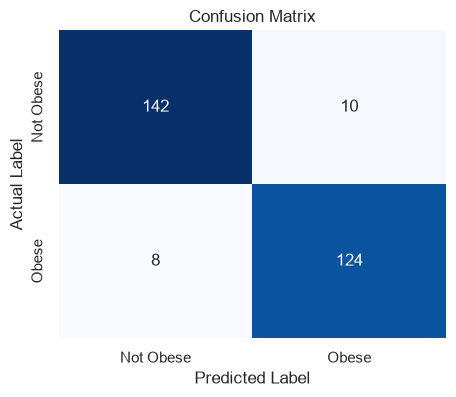

In [945]:
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not Obese", "Obese"],
    yticklabels=["Not Obese", "Obese"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

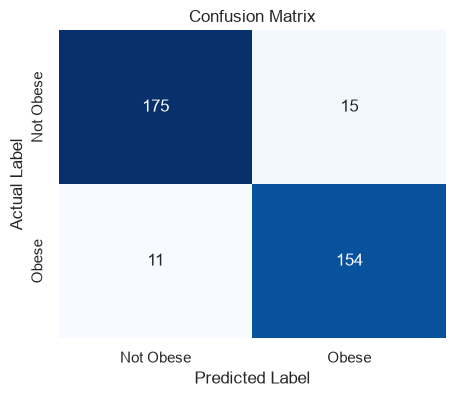

In [946]:
cm = confusion_matrix(test_Q2_y, y_test_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not Obese", "Obese"],
    yticklabels=["Not Obese", "Obese"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

e_in: 0.03083700440528636
e_eval: 0.06338028169014087
e_test: 0.07323943661971832


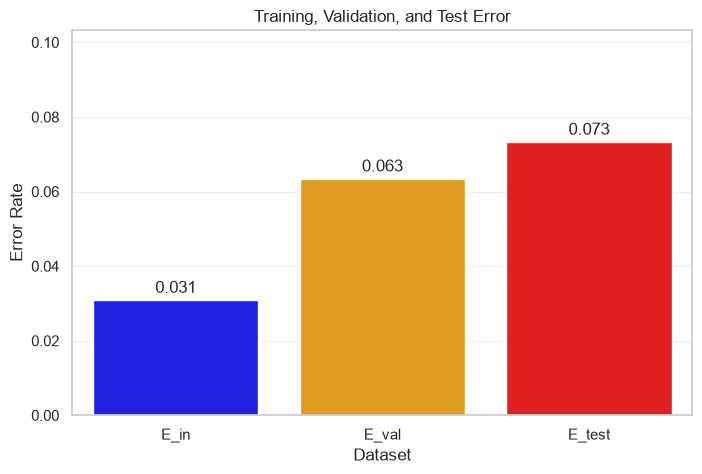

In [948]:
# Predictions
train_pred = best_model.predict(X_train)
val_pred = best_model.predict(X_val)
test_pred = best_model.predict(test_Q2_X)

# Calculate errors
e_in = 1 - accuracy_score(y_train, train_pred)
e_eval = 1 - accuracy_score(y_val, val_pred)
e_test = 1 - accuracy_score(test_Q2_y, test_pred)

print("e_in:", e_in)
print("e_eval:", e_eval)
print("e_test:", e_test)

error_data = pd.DataFrame({
    "Dataset": ["E_in", "E_val", "E_test"],
    "Error": [e_in, e_eval, e_test]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=error_data,
    x="Dataset",
    y="Error",
    hue="Dataset",
    palette=["blue", "orange", "red"],
    legend=False
)

for i, value in enumerate(error_data["Error"]):
    plt.text(
        i,
        value + 0.002,
        f"{value:.3f}",
        ha="center"
    )

plt.title("Training, Validation, and Test Error")
plt.xlabel("Dataset")
plt.ylabel("Error Rate")
plt.ylim(0, max(error_data["Error"]) + 0.03)
plt.grid(axis="y", alpha=0.3)

plt.show()